In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


# Paper figures and tables (Computers 13, 176)

Rebuilds Figures 7-12 and the result tables from the campaign stored in `RPINN/Data/v1-paper-run` (mixture repetitions, 27 gas models, IPOPT solutions and the same-session timing units). Everything is written to `RPINN/Results/v1-paper`. Nothing is trained here: the notebook only reads the stored campaign. The per-sample gas metrics are cached in `gas_per_sample.csv`; delete that file to recompute them from the 27 models (slow).

In [2]:
import sys
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from RPINN import paper_figures as pf

done = pf.build(pf.RUN, pf.OUT)
for k, v in done.items():
    print(k, v)

(CVXPY) Nov 26 11:32:27 PM: Encountered unexpected exception importing solver XPRESS:
AttributeError("module 'xpress' has no attribute 'getversion'")


fig7 ['/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig7_mixture_prediction_weights.pdf', '/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig7_mixture_prediction_weights.png']
fig8 ['/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig8_mixture_mape.pdf', '/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig8_mixture_mape.png']
table_mixture /Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/table_mixture.csv
fig9 ['/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig9_gas_losses.pdf', '/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v1-paper/fig9_gas_losses.png']
fig10 ['/Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Results/v

## Figure 7: mixture model, predicted output and recovered weights.

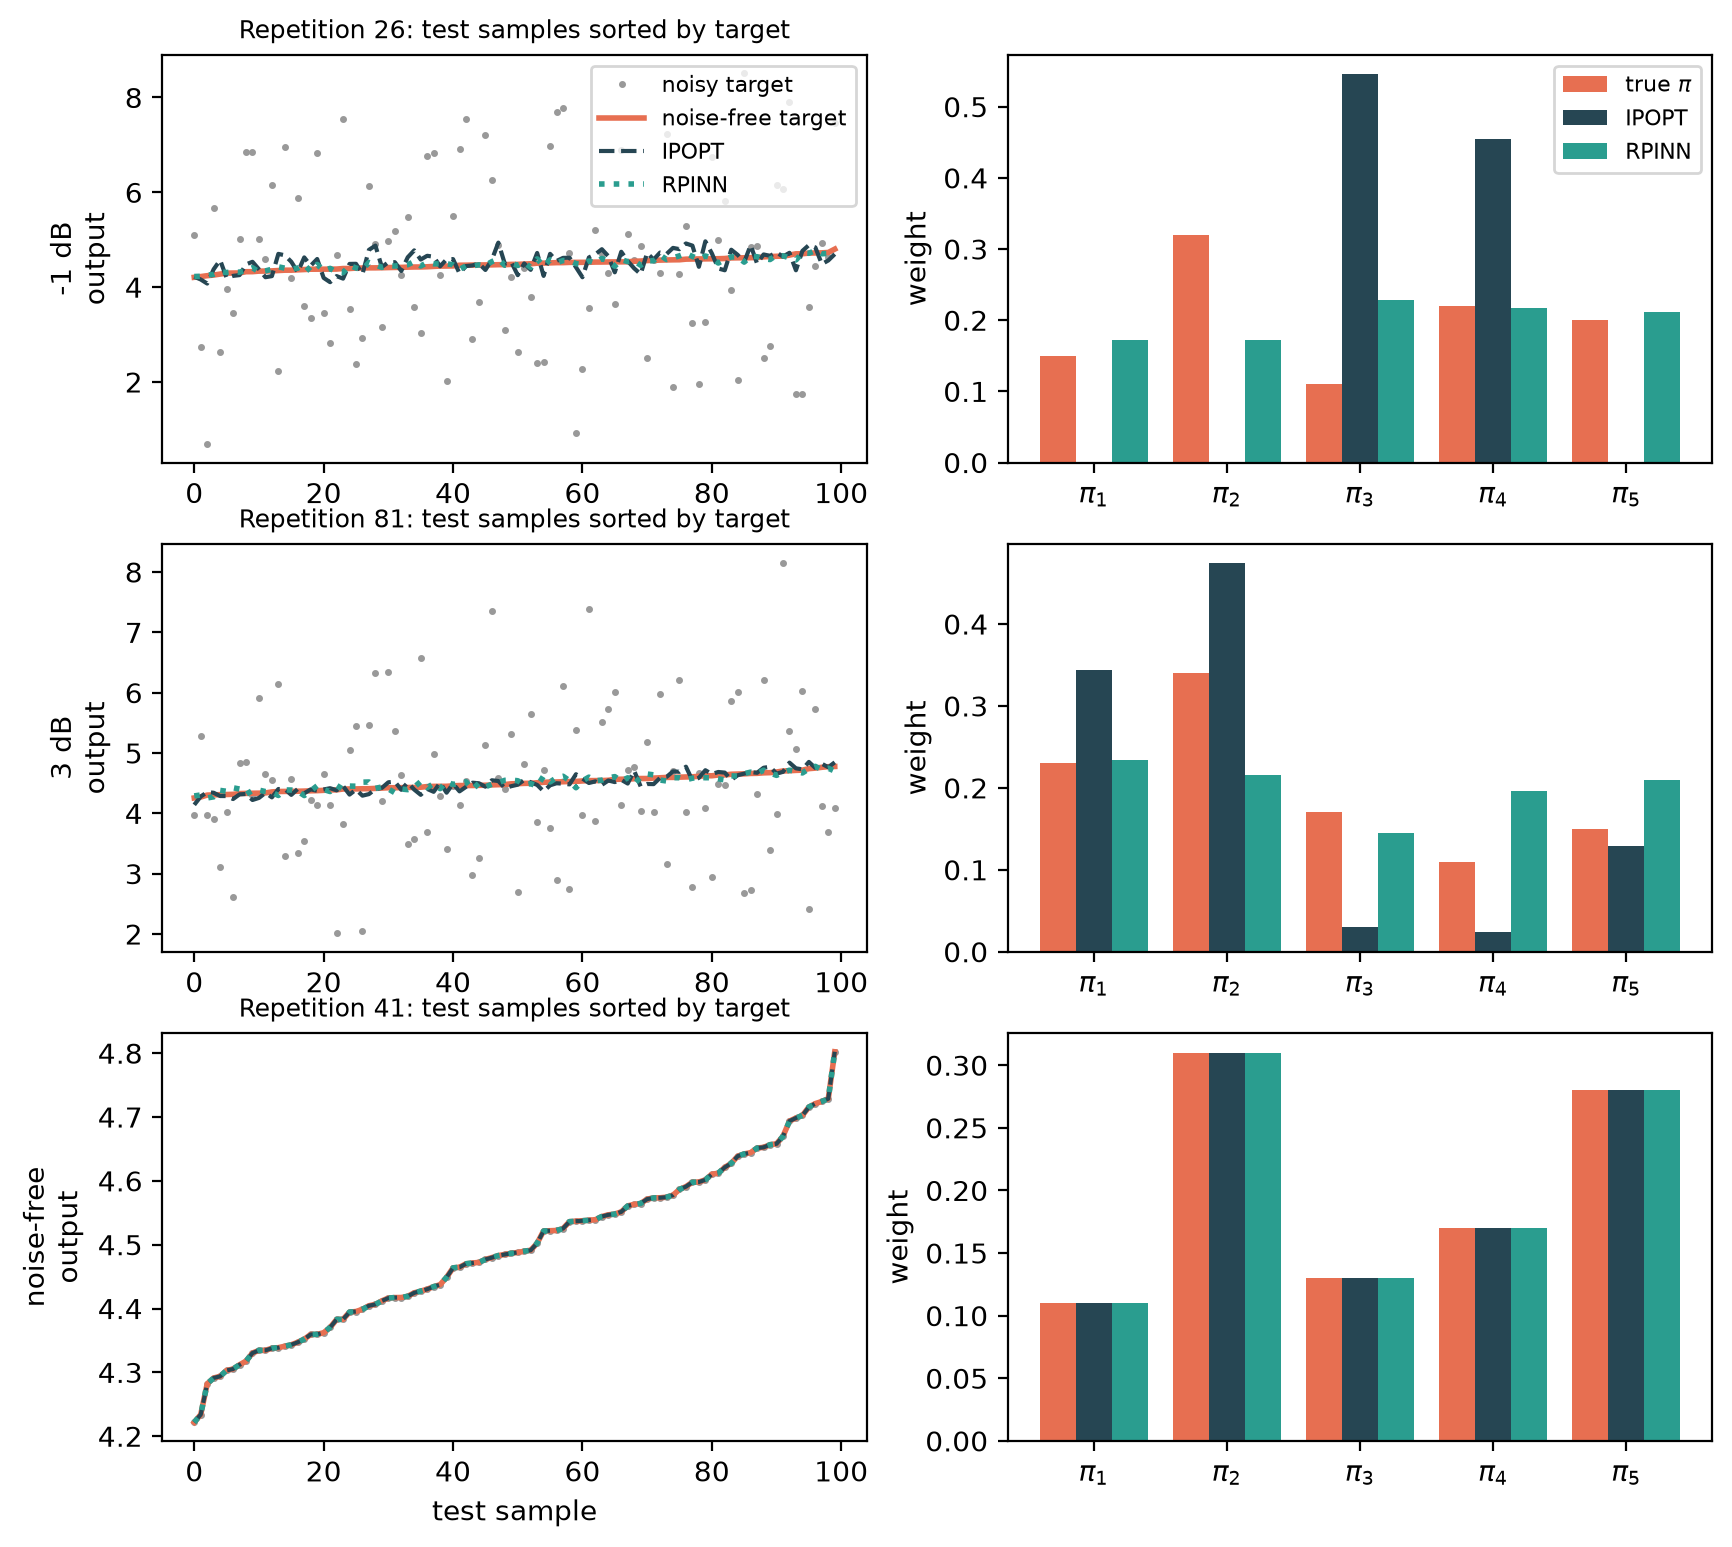

In [3]:
for f in done['fig7']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Figure 8: mixture model, error (MAPE) of output and weights per noise level.

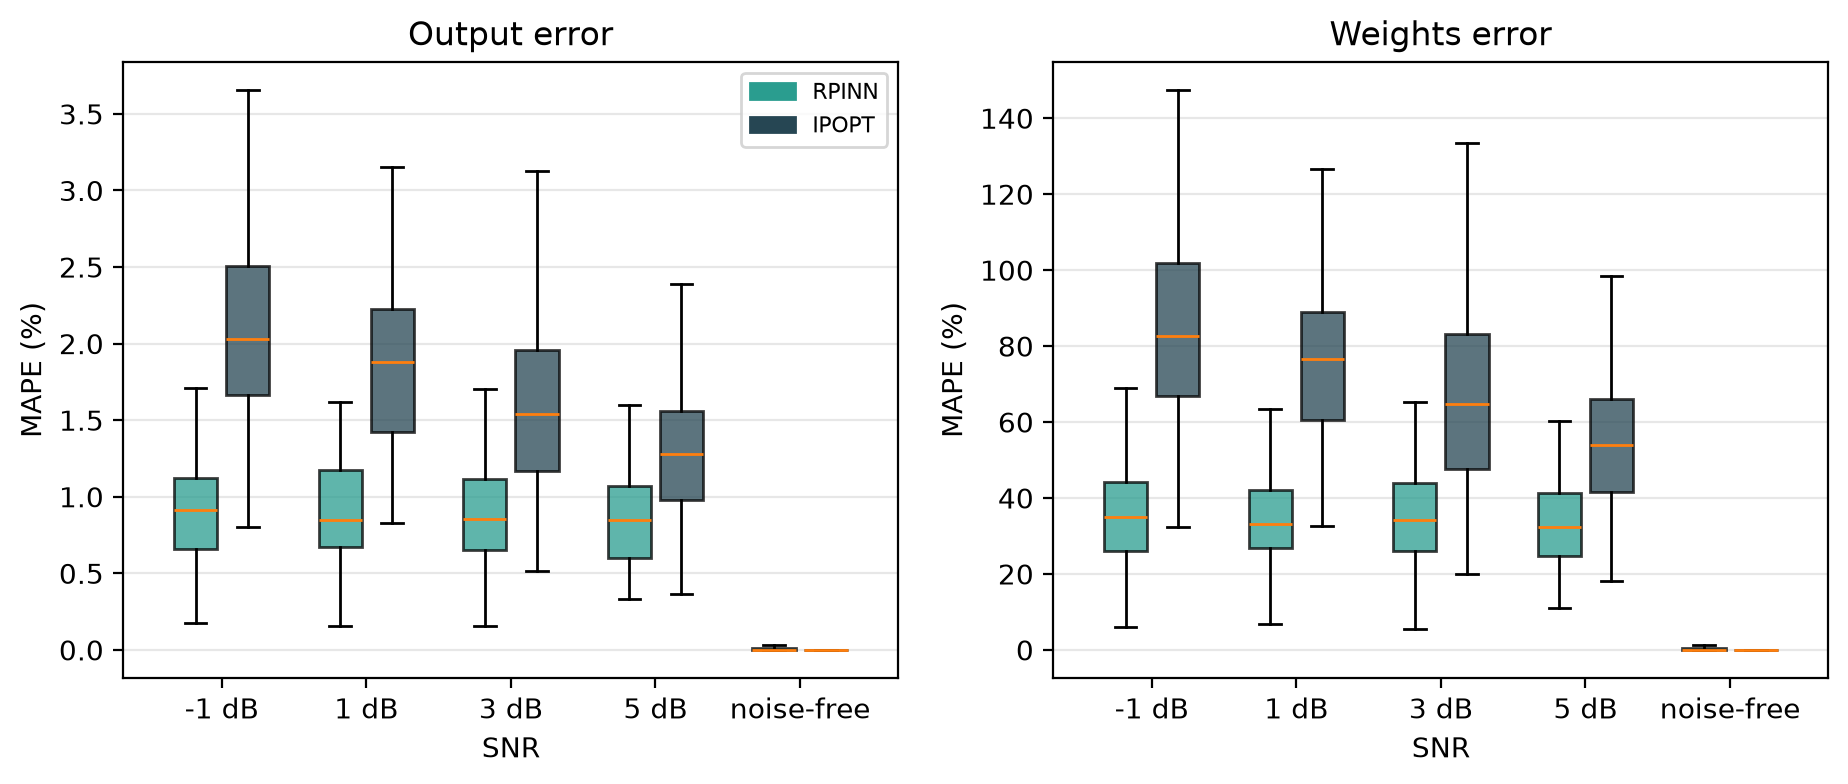

In [4]:
for f in done['fig8']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Figure 9: training losses, scenario S, network 8.

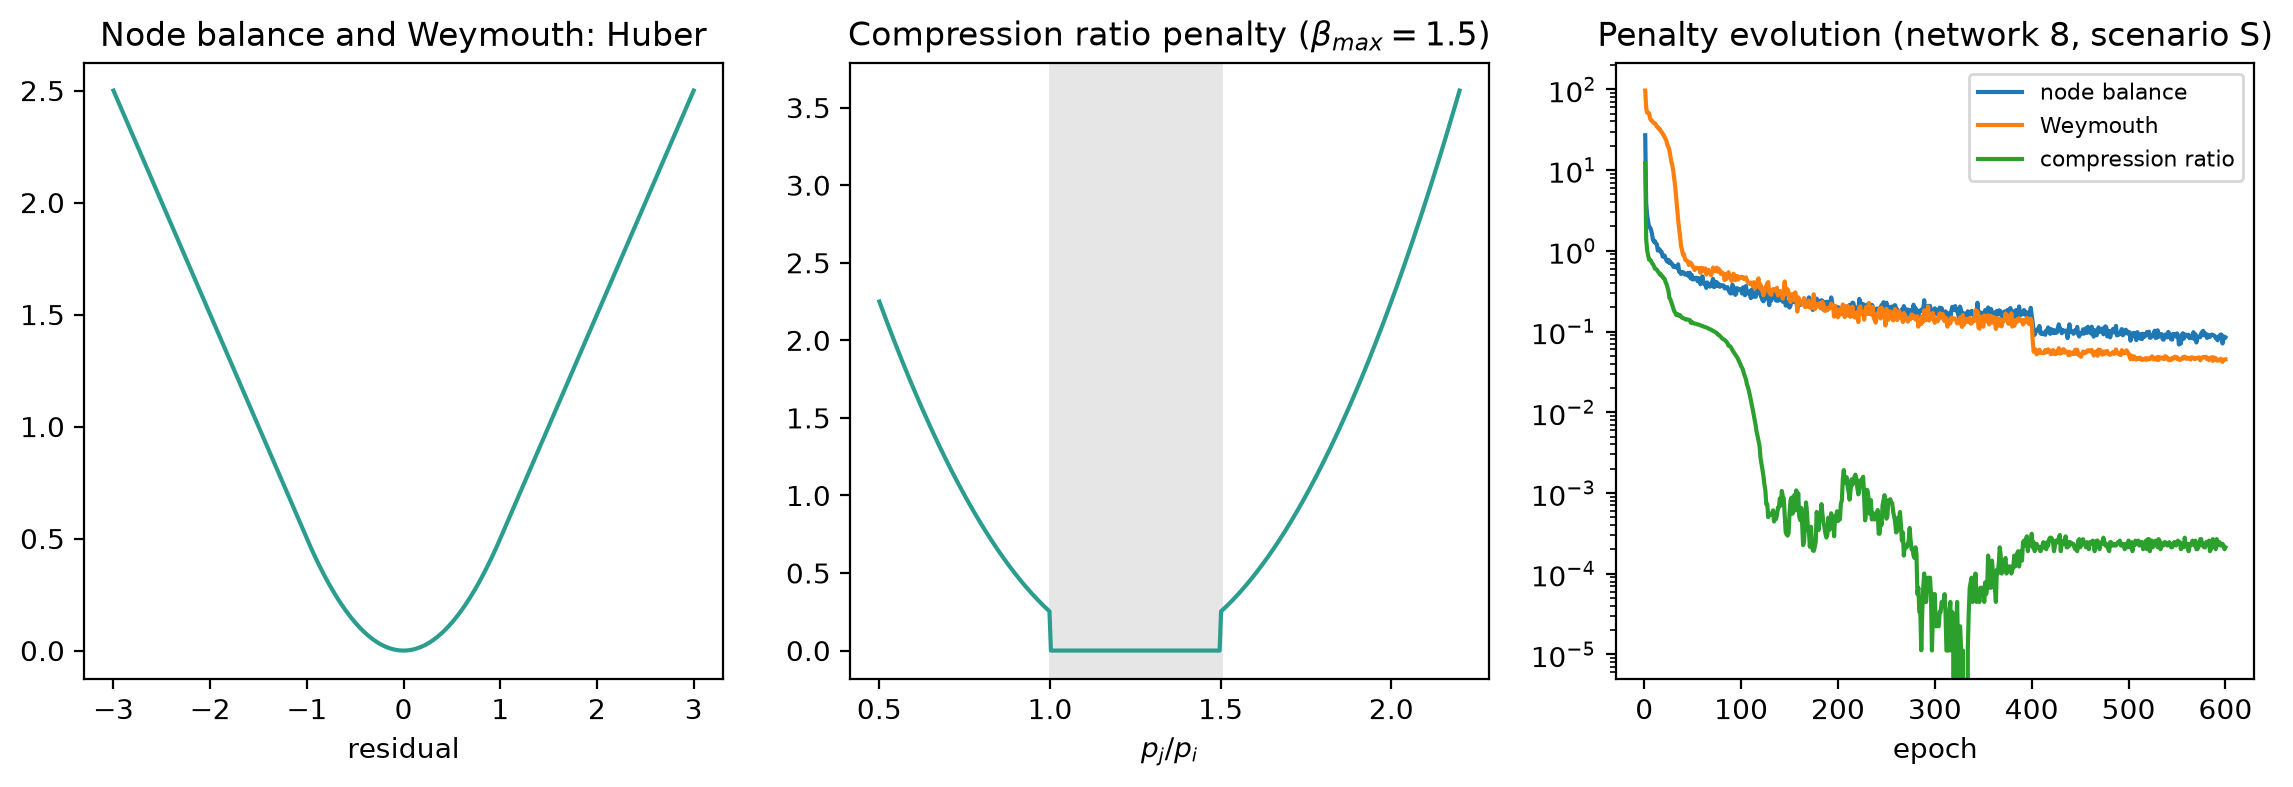

In [5]:
for f in done['fig9']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Figure 10: constraint compliance, network 8.

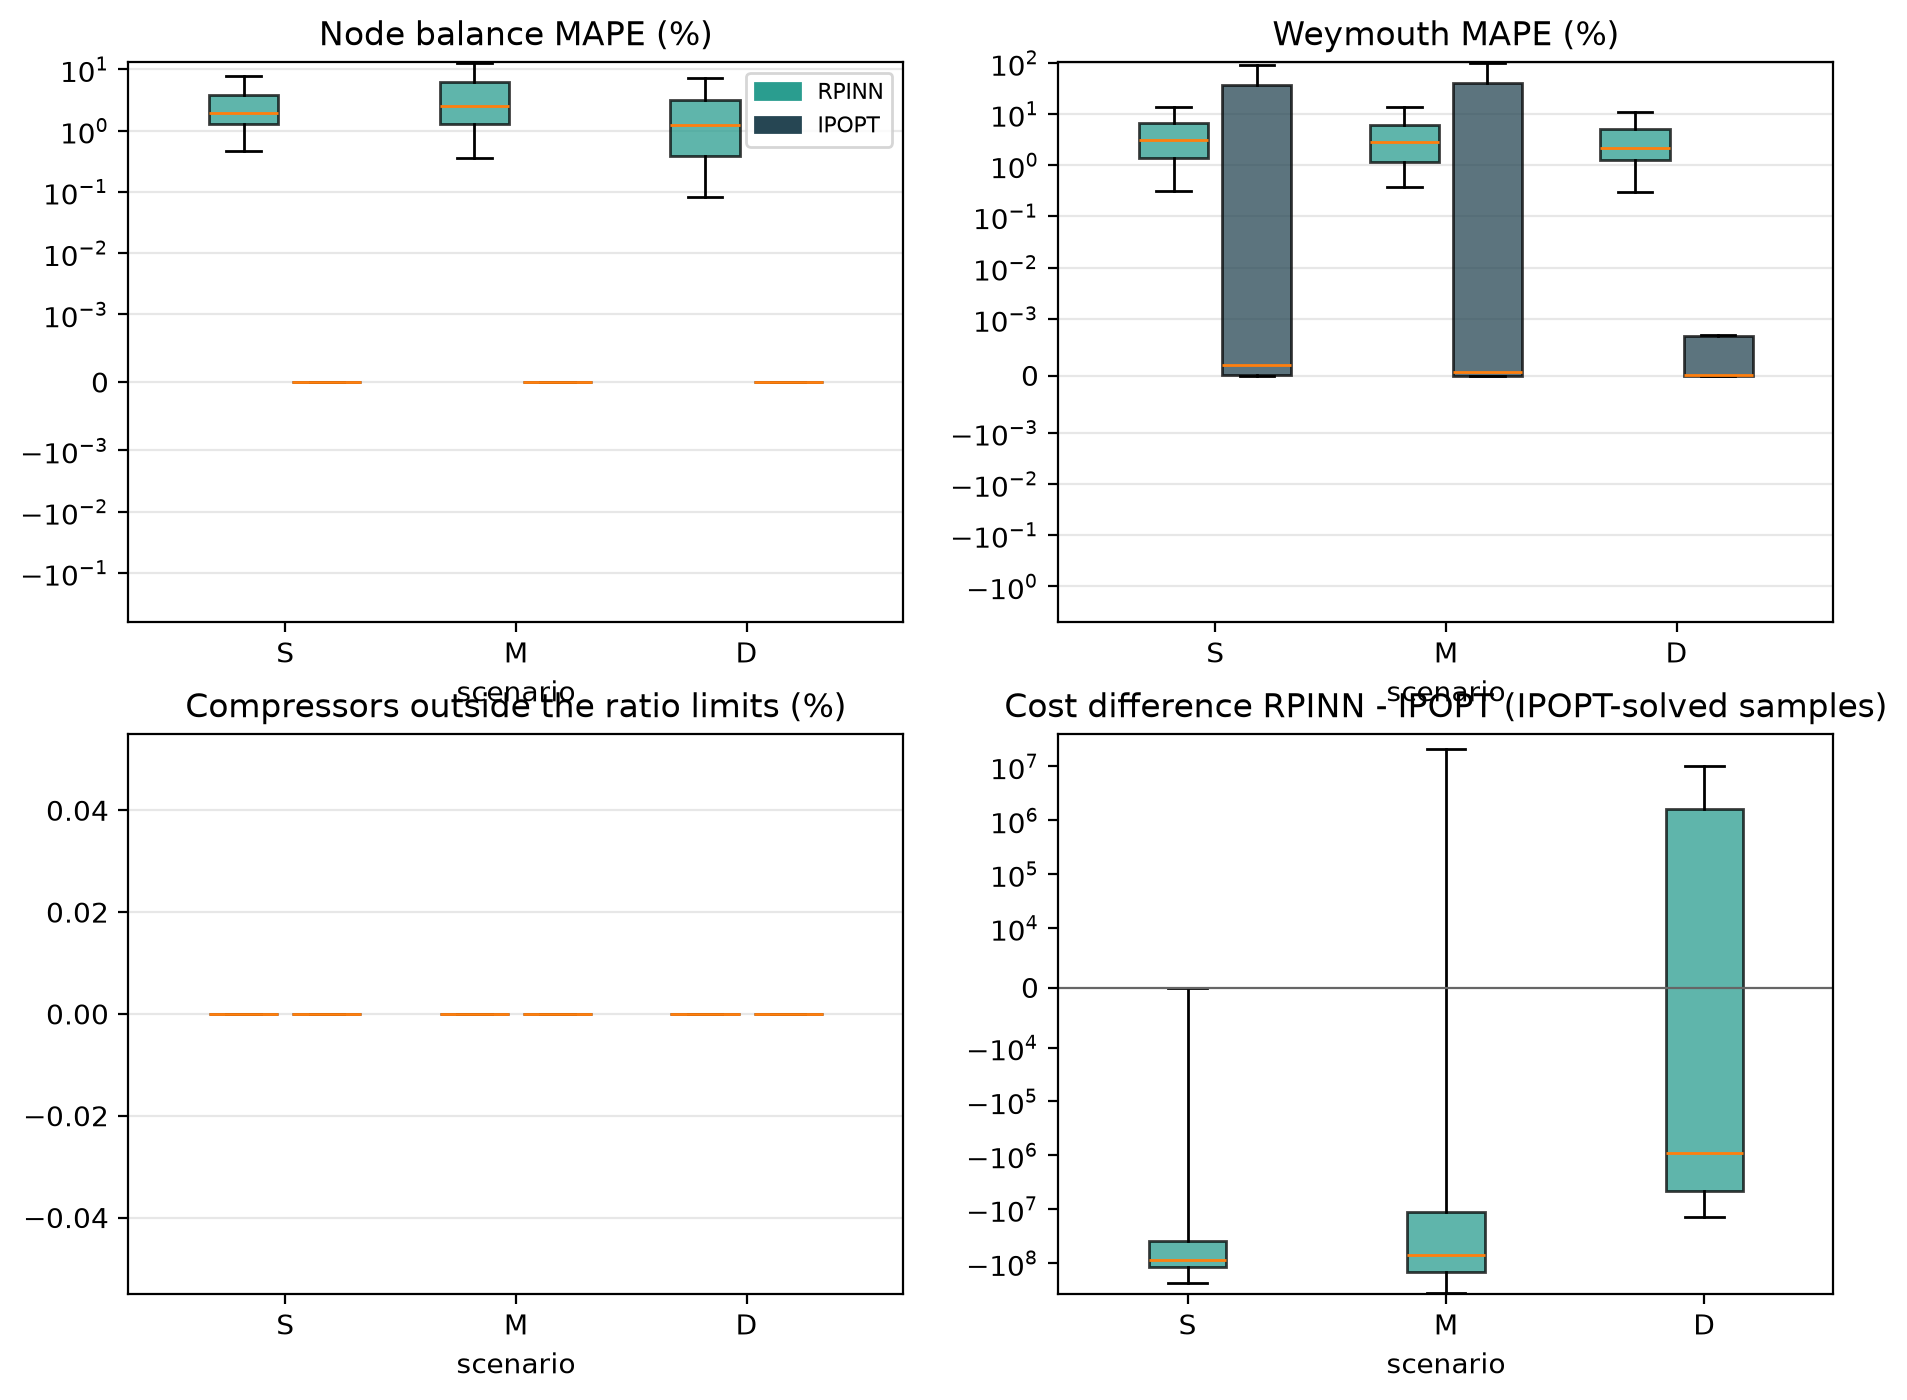

In [6]:
for f in done['fig10']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Figure 11: variable bounds, scenario S, network Col.

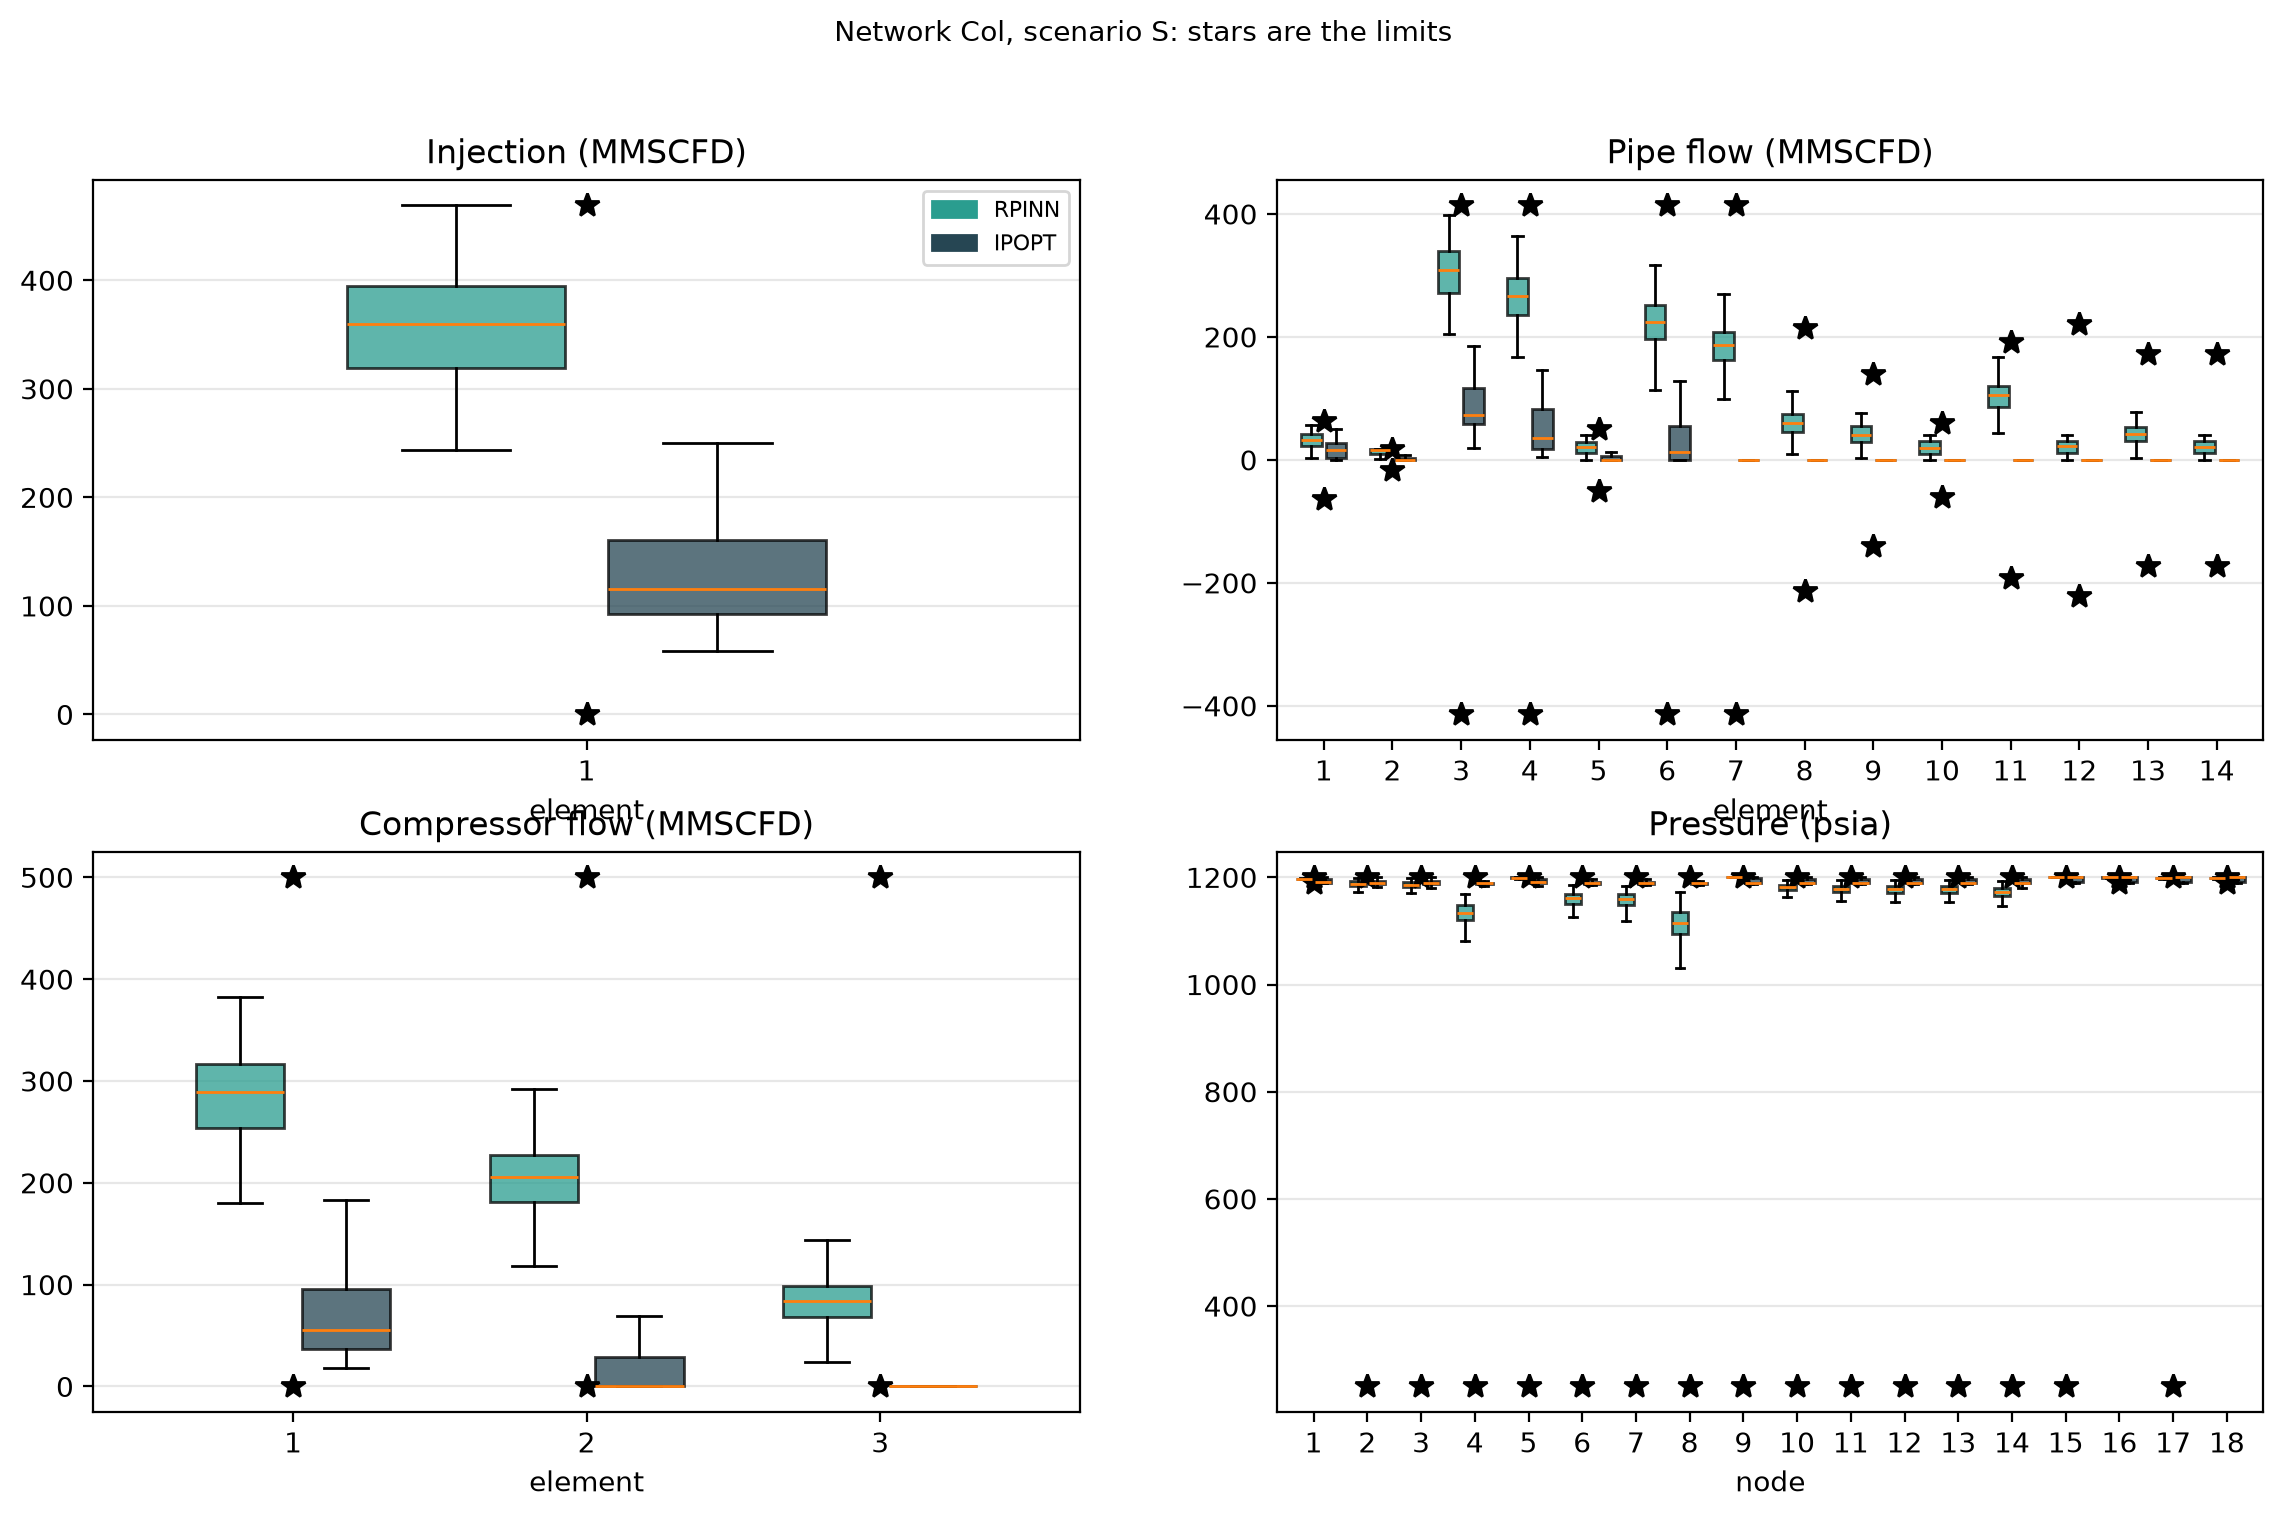

In [7]:
for f in done['fig11']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Figure 12: training, prediction and IPOPT times, scenario M.

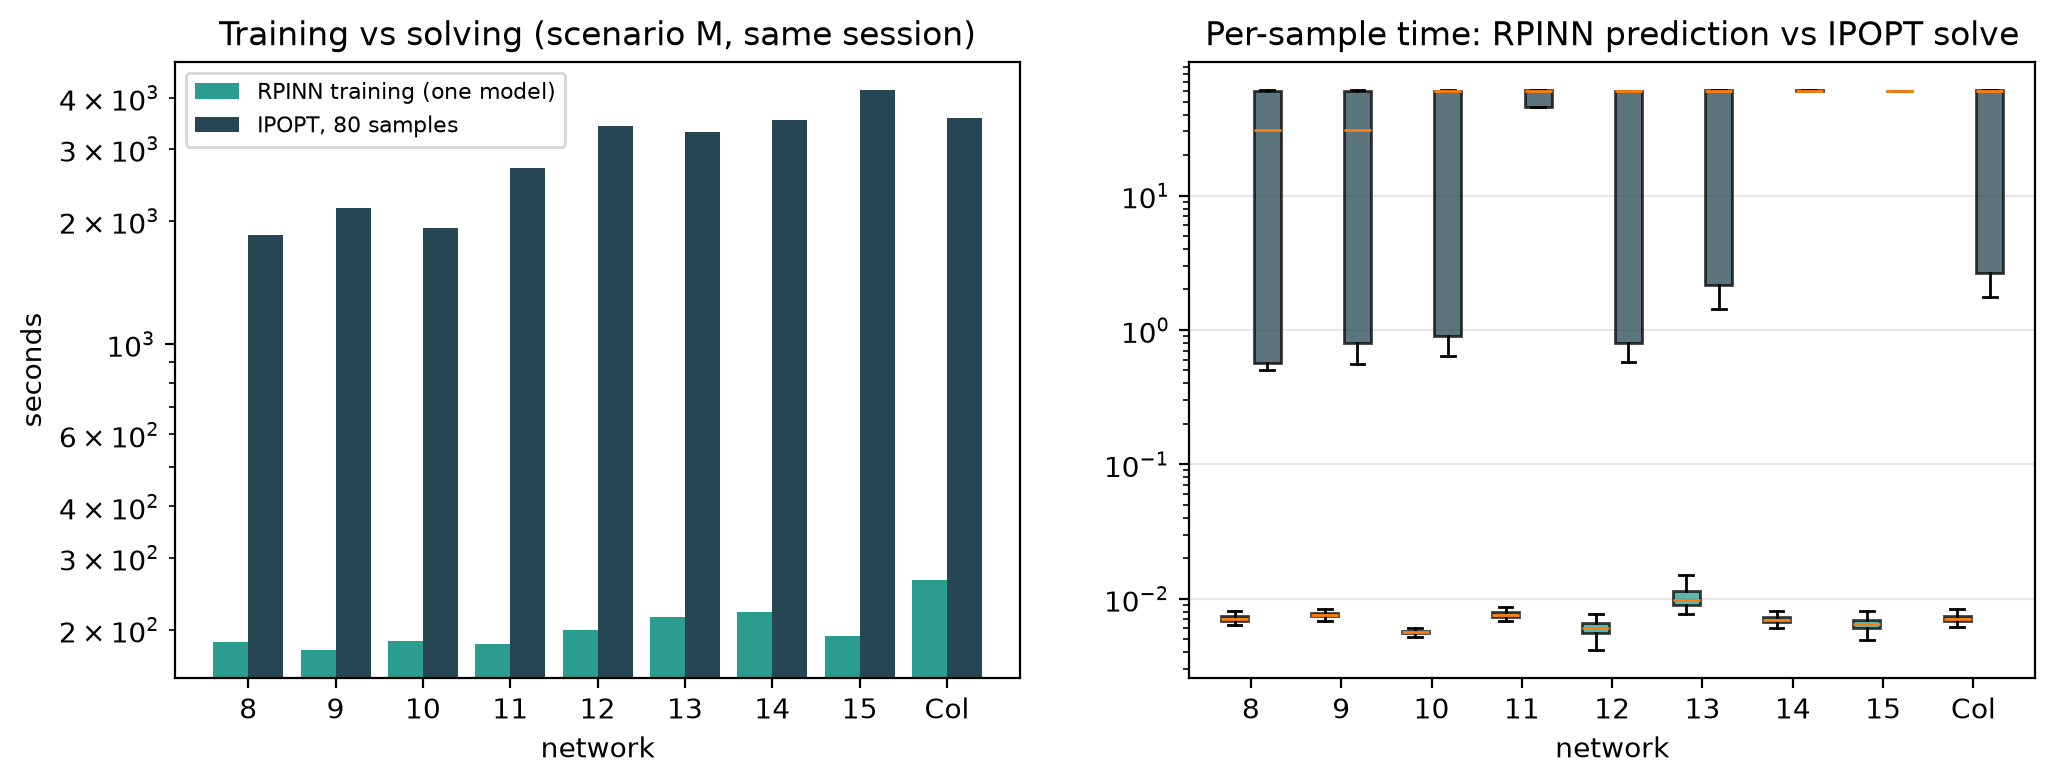

In [8]:
for f in done['fig12']:
    if f.endswith('.png'):
        display(Image(filename=f))

## Tables

In [9]:
display(pd.read_csv(pf.OUT / 'table_mixture.csv'))
display(pd.read_csv(pf.OUT / 'table_gas.csv'))
display(pd.read_csv(pf.OUT / 'table_times.csv'))

,snr,method,output_mape,weights_mape,seconds
0,-1 dB,RPINN,0.913481,34.862165,10.841850
1,-1 dB,IPOPT,2.032308,82.686895,0.060009
2,1 dB,RPINN,0.849628,33.243614,9.485966
3,1 dB,IPOPT,1.876586,76.552717,0.060945
4,3 dB,RPINN,0.854663,34.248564,9.309359
5,3 dB,IPOPT,1.540356,64.737772,0.061143
6,5 dB,RPINN,0.850382,32.229299,9.415688
7,5 dB,IPOPT,1.281365,53.872503,0.060751
8,noise-free,RPINN,0.001371,0.064398,9.255374
9,noise-free,IPOPT,0.000002,0.000069,0.060412


,scenario,network,ipopt_converged,samples,rpinn_balance_median,ipopt_balance_median,rpinn_weymouth_median,ipopt_weymouth_median,rpinn_ratio_median,ipopt_ratio_median,cost_diff_median,cost_diff_rel_median_pct
0,S,8,175,320,1.965295,4.608786e-09,3.052107,1.809096e-04,0.0,0.0,-8.706163e+07,-99.641486
1,S,9,178,320,2.115752,4.003907e-09,3.428223,1.748821e-04,0.0,0.0,-7.679947e+07,-99.607308
2,S,10,196,320,1.819880,4.399243e-09,3.985012,3.238691e-04,0.0,0.0,-8.821861e+07,-99.661844
3,S,11,132,320,1.473416,3.621781e-09,4.371973,1.203584e-04,0.0,0.0,-9.617929e+07,-99.696150
4,S,12,87,320,1.308863,3.804888e-09,4.781298,5.043549e-04,0.0,0.0,-1.121831e+08,-99.736003
5,S,13,78,320,1.430451,3.189835e-09,5.281161,6.930573e-03,0.0,0.0,-1.762802e+08,-99.806219
6,S,14,77,320,2.599655,4.317759e-09,4.798661,9.836469e-01,0.0,0.0,-1.431417e+08,-99.771649
7,S,15,43,320,3.111442,4.525240e-09,5.493038,1.782169e-03,0.0,0.0,-1.520173e+08,-99.799253
8,S,Col,62,320,6.755672,2.447918e-09,1.633608,1.669764e-06,0.0,0.0,-2.261461e+09,-99.941626
9,M,8,207,320,2.542560,3.479852e-09,2.808817,5.754572e-05,0.0,0.0,-7.239231e+07,-82.369582


,tip,net,s,cpu,rpinn_train_seconds,ipopt_seconds_total_80,ipopt_seconds_median,rpinn_predict_seconds_median,timing_cpu,timing_ipopt_seconds_median,timing_ipopt_converged,timing_ipopt_samples,timing_ipopt_converged_seconds_median
0,S,8,0,Intel(R) Xeon(R) CPU @ 2.20GHz,147.684096,2438.338686,30.775224,0.007010,Intel(R) Xeon(R) CPU @ 2.20GHz,0.927043,10,20,0.637195
1,S,8,1,Intel(R) Xeon(R) CPU @ 2.20GHz,156.621390,2438.338686,30.775224,0.007010,Intel(R) Xeon(R) CPU @ 2.20GHz,0.927043,10,20,0.637195
2,S,9,0,Intel(R) Xeon(R) CPU @ 2.20GHz,206.750379,1849.673948,0.859651,0.007214,Intel(R) Xeon(R) CPU @ 2.20GHz,0.698567,16,20,0.680404
3,S,9,1,Intel(R) Xeon(R) CPU @ 2.20GHz,210.630718,1849.673948,0.859651,0.007214,Intel(R) Xeon(R) CPU @ 2.20GHz,0.698567,16,20,0.680404
4,S,10,0,Intel(R) Xeon(R) CPU @ 2.20GHz,169.113649,1853.359678,0.997148,0.007582,Intel(R) Xeon(R) CPU @ 2.20GHz,1.234422,11,20,1.084964
5,S,10,1,Intel(R) Xeon(R) CPU @ 2.20GHz,176.547930,1853.359678,0.997148,0.007582,Intel(R) Xeon(R) CPU @ 2.20GHz,1.234422,11,20,1.084964
6,S,11,0,Intel(R) Xeon(R) CPU @ 2.20GHz,171.701774,2332.015672,1.499827,0.008425,Intel(R) Xeon(R) CPU @ 2.20GHz,1.516621,10,20,0.977080
7,S,11,1,Intel(R) Xeon(R) CPU @ 2.20GHz,175.026154,2332.015672,1.499827,0.008425,Intel(R) Xeon(R) CPU @ 2.20GHz,1.516621,10,20,0.977080
8,S,12,0,Intel(R) Xeon(R) CPU @ 2.20GHz,195.361922,3641.854673,60.302946,0.007643,Intel(R) Xeon(R) CPU @ 2.20GHz,60.318926,7,20,0.984116
9,S,12,1,Intel(R) Xeon(R) CPU @ 2.20GHz,203.704649,3641.854673,60.302946,0.007643,Intel(R) Xeon(R) CPU @ 2.20GHz,60.318926,7,20,0.984116
